# RAG

In [30]:
import sys
from pathlib import Path

# Get parent directory (Thesis-Edvin)
sys.path.append(str(Path.cwd().parent))

In [31]:
from utils import *
from datasets import load_dataset
from rag import *

In [3]:
cwes = load_dataset("Eathus/cwe_view1000_list_gpt_few_cwe_desc_final_best", split="train")
cwes_df = cwes.to_pandas()

In [32]:
def create_ordered_cwe_dict(weakness, doc_density=CWE_doc_density.LIGHT, old=False):
    ret =  {
        "ID": weakness["ID"],
        "Description": weakness['Description'],
        **({"ExtendedDescription": weakness['ExtendedDescription']} if "ExtendedDescription" in weakness else {}),

    }
    
    if doc_density in [CWE_doc_density.NORM, CWE_doc_density.HEAVY] and "AlternateTerms" in weakness :
        ret["AlternateTerms"] = weakness["AlternateTerms"]
    
    if doc_density in [CWE_doc_density.HEAVY] :
        if "CommonConsequences" in weakness:
            ret["CommonConsequences"] = weakness["CommonConsequences"]
        if "AffectedResources" in weakness:
            ret["AffectedResources"] = weakness["AffectedResources"]
        if "ModesOfIntroduction" in weakness:
            ret["ModesOfIntroduction"] = weakness["ModesOfIntroduction"]
        if "BackgroundDetails" in weakness:
            ret["BackgroundDetails"] = weakness["BackgroundDetails"]
    

    if doc_density in [CWE_doc_density.NORM, CWE_doc_density.HEAVY]:
        if "Notes" in weakness:
            ret["Notes"] = weakness["Notes"]
        if "ObservedExamples" in weakness:
            ret["ObservedExamples"] = [ ex['Description'] for ex in weakness["ObservedExamples"]]        

    if "DemonstrativeExamples" in weakness:
        if doc_density in [CWE_doc_density.LIGHT, CWE_doc_density.NORM] :
            ret["DemonstrativeExample"] = weakness['DemonstrativeExamples'][0]
        else :
            ret["DemonstrativeExamples"] = weakness['DemonstrativeExamples']
    
    return ret

def create_ordered_cwe_document_old(weakness, doc_density=CWE_doc_density.LIGHT, old=False):
    # Core Metadata (Filterable Fields)
    metadata = {
        "CWE_ID": weakness["ID"],
        "Name": weakness["Name"],
        "Abstraction": CWE_abstraction[weakness["Abstraction"].upper()].value,
        "FunctionalAreas": weakness.get("FunctionalAreas", []),
        "AffectedResources": weakness.get("AffectedResources", []),
        "ExploitLikelihood": weakness.get("LikelihoodOfExploit"),
        "MappingUsage": weakness.get("MappingNotes", {}).get("Usage"),
        "Code_Languages": set(),  # Track all languages found in examples
    }

    if not old:
        metadata["Child_IDs"] = weakness["Children"]

    # Core content structure
    content_parts = [
        f"# CWE-{weakness['ID']}: {weakness['Name']}",
        f"\n## Description\n{weakness['Description']}",  # Core Definition
    ]
    if weakness.get("ExtendedDescription"):
        content_parts.append(
            f"\n## Extended Description\n{weakness.get('ExtendedDescription', '')}"
        )

    if doc_density in [CWE_doc_density.NORM, CWE_doc_density.HEAVY] and weakness.get(
        "AlternateTerms"
    ):
        content_parts.append("\n## Alternate Terms")
        content_parts.extend(
            f"\n- **{term['Term']}**: {term.get('Description', 'No description available')}"
            for term in weakness.get("AlternateTerms", [])
        )

    if doc_density in [CWE_doc_density.HEAVY]:
        if weakness.get("CommonConsequences"):
            content_parts.append("\n## Potential Consequences")
            for cons in weakness.get("CommonConsequences", []):
                content_parts.append(
                    f"\n- **Scope**: {', '.join(cons.get('Scope', []))}\n"
                    f"  **Impact**: {', '.join(cons.get('Impact', []))}\n"
                    f"  **Note**: {cons.get('Note', 'No additional notes')}"
                )
        # Then add remaining elements in logical order
        if weakness.get("AffectedResources"):
            content_parts.extend(
                [
                    f"\n## Affected Resources\n{', '.join(weakness.get('AffectedResources', []))}"
                ]
            )
        if weakness.get("ModesOfIntroduction"):
            content_parts.extend(
                [
                    f"\n## Modes of Introduction\n"
                    + "\n".join(
                        f"- {mode['Phase']}: {mode.get('Note','')}"
                        for mode in weakness.get("ModesOfIntroduction", [])
                    )
                ]
            )
        if weakness.get("BackgroundDetails"):
            bg_details = weakness["BackgroundDetails"]
            if isinstance(bg_details, list):
                bg_details = "\n".join(bg_details)
            content_parts.append(f"\n## Background\n{bg_details[:2000]}")

    if doc_density in [CWE_doc_density.NORM, CWE_doc_density.HEAVY]:
        if weakness.get("Notes"):
            notes = [
                (note.get("Type", "General"), note["Note"])
                for note in weakness["Notes"]
                if note.get("Type")
                in [
                    "Technical",
                    "Relationship",
                    "Theoretical",
                    "Terminology",
                    "Applicable Platform",
                ]
            ]
            if notes:
                content_parts.append("\n## Notes")
                content_parts.extend(f"\n- **{ty}**: {note}" for ty, note in notes)

        # Observed Examples
        if weakness.get("ObservedExamples"):
            content_parts.append("\n## Observed Cases")
            content_parts.extend(
                f"\n- {ex['Description']}"  # removed (Ref: {ex.get('Reference','')})
                for ex in weakness["ObservedExamples"]
            )

    if weakness.get("DemonstrativeExamples"):
        content_parts.append("\n## Demonstrative Scenario")

        def format_code_block(code, language):
            # Normalize language tag
            language = (language or "").lower().strip()
            language = re.sub(r" ", "_", language)

            # Remove ALL leading/trailing backticks and whitespace
            code = re.sub(r"^[\s`]*", "", code)
            code = re.sub(r"[\s`]*$", "", code)

            # Remove empty lines at start/end
            code = re.sub(r"^\n+", "", code)
            code = re.sub(r"\n+$", "", code)

            code = re.sub(r"`{3,}", "", code)
            return (
                f"```{language}\n{code}\n```"
                if language and language != "other"
                else f"```\n{code}\n```"
            )

        examples = (
            [weakness["DemonstrativeExamples"][0]]
            if doc_density in [CWE_doc_density.LIGHT]
            else weakness["DemonstrativeExamples"]
        )
        for i, example_group in enumerate(examples):
            example_content = []
            pre_code_text = []
            post_code_text = []
            vulnerable_code = ""
            language = ""

            # First pass: Collect all components in order
            for entry in example_group.get("Entries", []):
                if "IntroText" in entry:
                    pre_code_text.append(entry["IntroText"])
                elif "BodyText" in entry:
                    if vulnerable_code:
                        post_code_text.append(entry["BodyText"])
                    else:
                        pre_code_text.append(entry["BodyText"])
                elif entry.get("Nature") == "Bad" and "ExampleCode" in entry:
                    vulnerable_code = entry["ExampleCode"]
                    language = entry.get("Language", "")
                    metadata["Code_Languages"].add(language)

            # Build the example with proper flow
            if pre_code_text:
                #example_content.append("\n### Scenario")  # + str(i + 1)
                example_content.extend(f"\n{text}" for text in pre_code_text)

            if vulnerable_code:
                example_content.append(
                    "\n### Vulnerable"
                    + (" " + language if language and language != "other" else "")
                    + " Code"
                )
                example_content.append(format_code_block(vulnerable_code, language))

            if post_code_text:
                example_content.append("\n### Analysis")
                example_content.extend(f"\n{text}" for text in post_code_text)

            content_parts.extend(example_content)

    # Convert language set to list in metadata
    metadata["Code_Languages"] = list(metadata["Code_Languages"])

    return Document(page_content="\n".join(content_parts), metadata=metadata)


def split_cwe_document(doc: Document, max_tokens: int = 800) -> List[Document]:
    """
    Splits documents with chunk reassembly capability through metadata.
    Prioritizes:
    1. Keeping examples/scenarios intact
    2. Preserving section boundaries
    3. Adding reassembly metadata
    """
    if count_tokens(doc.page_content) <= max_tokens:
        # Add chunk metadata even for unsplit documents
        doc.metadata.update(
            {
                "chunk_id": f"{doc.metadata['CWE_ID']}_0",
                "total_chunks": 1,
                "chunk_hash": hashlib.md5(doc.page_content.encode()).hexdigest(),
            }
        )
        return [doc]

    splitter = RecursiveCharacterTextSplitter(
        chunk_size=max_tokens,
        chunk_overlap=100,
        length_function=count_tokens,
        separators=[
            "\n\nScenario ",  # Split between demonstrative examples
            "\n\n## ",  # Section headers
            "\n\n",  # Paragraph breaks
            "```\n",  # End of code blocks
            "\n",  # Line breaks
            " ",  # Last resort
        ],
        keep_separator=True,
    )

    chunks = splitter.split_text(doc.page_content)
    doc_hash = hashlib.md5(doc.page_content.encode()).hexdigest()

    return [
        Document(
            page_content=f"# CWE-{doc.metadata['CWE_ID']} (Part {i+1}/{len(chunks)})\n{chunk}",
            metadata={
                **doc.metadata,  # Preserve original metadata
                **{
                    "chunk_id": f"{doc.metadata['CWE_ID']}_{i}",
                    "total_chunks": len(chunks),
                    "chunk_sequence": i,
                    "parent_hash": doc_hash,
                    "chunk_hash": hashlib.md5(chunk.encode()).hexdigest(),
                    "is_code_chunk": "```" in chunk,
                },
            },
        )
        for i, chunk in enumerate(chunks)
    ]

In [44]:
import pandas as pd

# Load the DataFrame from the .pkl file
cwes_df = pd.read_pickle("tmp/gpt_cwe_desc_few_df_final6.pkl")
import json

mask = cwes_df["gpt_cwe_description"].str.contains(
    r"^\{\"gpt_cwe_description\":", na=False
)
cwes_df.loc[mask, "gpt_cwe_description"] = cwes_df.loc[
    mask, "gpt_cwe_description"
].apply(lambda x: json.loads(x)["gpt_cwe_description"])

In [11]:
cwes_df["gpt_cwe_description"]

0      # CWE-284: Improper Access Control\n\n## Descr...
1      # CWE-1191: On-Chip Debug and Test Interface W...
2      # CWE-1220: Insufficient Granularity of Access...
3      # CWE-1222: Insufficient Granularity of Addres...
4      # CWE-1224: Improper Restriction of Write-Once...
                             ...                        
935    # CWE-1102: Reliance on Machine-Dependent Data...
936    # CWE-1103: Use of Platform-Dependent Third Pa...
937    # CWE-474: Use of Function with Inconsistent I...
938    # CWE-589: Call to Non-ubiquitous API\n\n## De...
939    # CWE-562: Return of Stack Variable Address\n\...
Name: gpt_cwe_description, Length: 940, dtype: object

In [26]:
cwes_df.columns

Index(['ID', 'Name', 'Abstraction', 'Structure', 'Status', 'Description',
       'ExtendedDescription', 'ApplicablePlatforms', 'AlternateTerms',
       'ModesOfIntroduction', 'CommonConsequences', 'PotentialMitigations',
       'ObservedExamples', 'AffectedResources', 'TaxonomyMappings',
       'RelatedAttackPatterns', 'References', 'Notes', 'ContentHistory',
       'MappingNotes_Usage', 'MappingNotes_Rationale', 'MappingNotes_Comments',
       'MappingNotes_Reasons', 'MappingNotes_Suggestions', 'RelatedWeaknesses',
       'WeaknessOrdinalities', 'DetectionMethods', 'DemonstrativeExamples',
       'FunctionalAreas', 'Diagram', 'LikelihoodOfExploit',
       'BackgroundDetails', 'NumPaths', 'Paths', 'Children', 'Summary',
       'gpt_cwe_description', 'RAG_Doc'],
      dtype='object')

In [ ]:
cwes_df.gpt_cwe_description[0]

In [53]:
data["Weaknesses"][0].get("MappingNotes", {}).get("Usage")

'Discouraged'

In [45]:
from langchain.schema import Document
from rag import *
import pandas as pd
import json

with open("tmp/view_CWE-1000_all_weaknesses.json", "r") as file:
    data = json.load(file)
#display(data)
old_documents = [
    create_ordered_cwe_document_old(weakness, old=True) for weakness in data["Weaknesses"]
]
display(old_documents[0].metadata)
document_dict = {doc.metadata["CWE_ID"]: doc for doc in old_documents}
cwes_df["RAG_Doc"] = cwes_df.apply(
    lambda x: Document(
        page_content=x.gpt_cwe_description,
        metadata={
            **document_dict[x.ID].metadata,  # Original metadata
            "Abstraction": CWE_abstraction[x.Abstraction.upper()].value,  # New field
            #"Child_IDs": x.Children.tolist(),  # New field
        },
    ),
    axis=1,
)
documents = [
    Document(
        page_content=cwe.gpt_cwe_description,
        metadata={
            **document_dict[cwe.ID].metadata,  # Original metadata
            "Abstraction": CWE_abstraction[cwe.Abstraction.upper()].value,  # New field
            #"MappingUsage": cwe.MappingNotes_Usage
            #"Child_IDs": cwe.Children.tolist(),  # New field
        },
    )
    for _, cwe in cwes_df.iterrows()
]

{'CWE_ID': '284',
 'Name': 'Improper Access Control',
 'Abstraction': 4,
 'FunctionalAreas': [],
 'AffectedResources': ['File or Directory'],
 'ExploitLikelihood': None,
 'MappingUsage': 'Discouraged',
 'Code_Languages': []}

In [46]:
def has_markdown_section(markdown_text, section_title, level=None):
    """
    Checks if a section with the given title exists in the Markdown text.

    Args:
        markdown_text (str): The Markdown-formatted string.
        section_title (str): The section heading to look for.
        level (int, optional): The heading level (1 for '#', 2 for '##', etc.).
                               If None, any level is matched.

    Returns:
        bool: True if the section exists, False otherwise.
    """
    if level is not None:
        pattern = rf'^\s*{"#" * level}\s+{re.escape(section_title)}\s*$'
    else:
        pattern = rf'^\s*#+\s+{re.escape(section_title)}\s*$'
    
    return re.search(pattern, markdown_text, re.MULTILINE) is not None

In [28]:
l = 0
for doc in documents :
    if not has_markdown_section(doc.page_content, "Scenario", 3) :
        l += 1

print(l)

0


In [29]:
from IPython.display import display, Markdown
display(Markdown(documents[9].page_content))

# CWE-1257: Improper Access Control Applied to Mirrored or Aliased Memory Regions

## Description
Aliased or mirrored memory regions in hardware designs may have inconsistent read/write permissions enforced by the hardware. A possible result is that an untrusted agent is blocked from accessing a memory region but is not blocked from accessing the corresponding aliased memory region.
			

## Extended Description


Hardware product designs often need to implement memory protection features that enable privileged software to define isolated memory regions and access control (read/write) policies. Isolated memory regions can be defined on different memory spaces in a design (e.g. system physical address, virtual address, memory mapped IO).


Each memory cell should be mapped and assigned a system address that the core software can use to read/write to that memory. It is possible to map the same memory cell to multiple system addresses such that read/write to any of the aliased system addresses would be decoded to the same memory cell.


This is commonly done in hardware designs for redundancy and simplifying address decoding logic. If one of the memory regions is corrupted or faulty, then that hardware can switch to using the data in the mirrored memory region. Memory aliases can also be created in the system address map if the address decoder unit ignores higher order address bits when mapping a smaller address region into the full system address.


A common security weakness that can exist in such memory mapping is that aliased memory regions could have different read/write access protections enforced by the hardware such that an untrusted agent is blocked from accessing a memory address but is not blocked from accessing the corresponding aliased memory address. Such inconsistency can then be used to bypass the access protection of the primary memory block and read or modify the protected memory.


An untrusted agent could also possibly create memory aliases in the system address map for malicious purposes if it is able to change the mapping of an address region or modify memory region sizes.


## Demonstrative Scenario

### Scenario

In a System-on-a-Chip (SoC) design the system fabric uses 16 bit addresses. An IP unit (Unit_A) has 4 kilobyte of internal memory which is mapped into a 16 kilobyte address range in the system fabric address map.

|  | 
|
|  System Address  |  Mapped to   |
|  0x0000 - 0x3FFF  |  Unit_A registers : 0x0000 - 0x0FFF   |
|  0x4000 - 0xFFFF  |  Other IPs & Memory   |

	
 To protect the register controls in Unit_A unprivileged software is blocked from accessing addresses between 0x0000 - 0x0FFF. 

	
 The address decoder of Unit_A masks off the higher order address bits and decodes only the lower 12 bits for computing the offset into the 4 kilobyte internal memory space.

#### Vulnerable Other Code
```
In this design the aliased memory address ranges are these:



0x0000 - 0x0FFF


0x1000 - 0x1FFF


0x2000 - 0x2FFF


0x3000 - 0x3FFF


 The same register can be accessed using four different addresses: 0x0000, 0x1000, 0x2000, 0x3000. 


 The system address filter only blocks access to range 0x0000 - 0x0FFF and does not block access to the aliased addresses in 0x1000 - 0x3FFF range. Thus, untrusted software can leverage the aliased memory addresses to bypass the memory protection.
```

In [47]:
old_norm_documents = [
    create_ordered_cwe_document_old(weakness, CWE_doc_density.NORM, old=True)
    for weakness in data["Weaknesses"]
]
old_heavy_documents = [
    create_ordered_cwe_document(weakness, CWE_doc_density.HEAVY, old=True)
    for weakness in data["Weaknesses"]
]
old_medium_documents = [
    create_ordered_cwe_document(weakness, CWE_doc_density.MEDIUM, old=True)
    for weakness in data["Weaknesses"]
]

In [48]:
allowed_values = {"Allowed", "Allowed-with-Review", "Discouraged"}

documents = [
    doc for doc in documents if doc.metadata.get("MappingUsage") in allowed_values
]
old_documents = [
    doc for doc in old_documents if doc.metadata.get("MappingUsage") in allowed_values
]
old_norm_documents = [
    doc
    for doc in old_norm_documents
    if doc.metadata.get("MappingUsage") in allowed_values
]
old_heavy_documents = [
    doc
    for doc in old_heavy_documents
    if doc.metadata.get("MappingUsage") in allowed_values
]
old_medium_documents = [
    doc
    for doc in old_medium_documents
    if doc.metadata.get("MappingUsage") in allowed_values
]

In [38]:
from IPython.display import display, Markdown

display(Markdown(documents[0].page_content))

# CWE-284: Improper Access Control

## Description
The product does not restrict or incorrectly restricts access to a resource from an unauthorized actor.

## Extended Description

Access control involves the use of several protection mechanisms such as:

  - Authentication (proving the identity of an actor)

  - Authorization (ensuring that a given actor can access a resource), and

  - Accountability (tracking of activities that were performed)

When any mechanism is not applied or otherwise fails, attackers can compromise the security of the product by gaining privileges, reading sensitive information, executing commands, evading detection, etc.

There are two distinct behaviors that can introduce access control weaknesses:

  - Specification: incorrect privileges, permissions, ownership, etc. are explicitly specified for either the user or the resource (for example, setting a password file to be world-writable, or giving administrator capabilities to a guest user). This action could be performed by the program or the administrator.

  - Enforcement: the mechanism contains errors that prevent it from properly enforcing the specified access control requirements (e.g., allowing the user to specify their own privileges, or allowing a syntactically-incorrect ACL to produce insecure settings). This problem occurs within the program itself, in that it does not actually enforce the intended security policy that the administrator specifies.

## Demonstrative Scenario

### Scenario
Consider a web application that allows users to view their own profiles but does not properly restrict access to other users' profiles.

#### Vulnerable PHP Code
```php
session_start();
$user_id = $_SESSION['user_id'];
$requested_profile_id = $_GET['profile_id'];

// No access control check
$query = "SELECT * FROM users WHERE id = '$requested_profile_id'";
$result = mysqli_query($conn, $query);
$profile = mysqli_fetch_assoc($result);
// Display profile information
```

#### Analysis
In this code, the application retrieves a user profile based on the `profile_id` parameter from the URL without checking if the currently authenticated user has permission to access that profile. An attacker could manipulate the `profile_id` parameter to access other users' profiles, leading to unauthorized information disclosure. This demonstrates a failure in both specification and enforcement of access control mechanisms.

In [49]:
import re
from IPython.display import display, Markdown, Latex


def remove_subtitle(markdown_text, subtitle_names):
    # Pattern to match the subtitle and all content until the next subtitle or end
    ret = markdown_text
    for name in subtitle_names:
        pattern = r"## " + re.escape(name) + r"\b.*?(?=\n## |\Z)"
        ret = re.sub(pattern, "", ret, flags=re.DOTALL | re.IGNORECASE)

    # Remove with flags for dot matching newline and case sensitivity
    return ret

In [50]:
bm25_docs0 = [
    Document(
        page_content=cwe.page_content,
        metadata=cwe.metadata,
    )
    for cwe in old_documents
]

In [51]:
bm25_docs1 = [
    Document(
        page_content=remove_subtitle(cwe.page_content, ["Extended Description"]),
        metadata=cwe.metadata,
    )
    for cwe in old_documents
]

In [52]:
bm25_docs2 = [
    Document(
        page_content=remove_subtitle(
            cwe.gpt_cwe_description, ["Extended Description", "Demonstrative Scenario"]
        ),
        metadata=document_dict[cwe.ID].metadata,
    )
    for _, cwe in cwes_df.iterrows()
]

In [53]:
l = [
    (cwe, i)
    for i, cwe in enumerate(bm25_docs1)
    if cwe.page_content.rstrip() != bm25_docs2[i].page_content.rstrip()
    and (
        "Extended Description" not in old_documents[i].page_content
        or "Demonstrative Scenario" not in old_documents[i].page_content
    )
]
print(len(l))

display(Markdown(documents[l[2][1]].page_content))
display(Markdown(bm25_docs2[l[1][1]].page_content))

print(documents[l[2][1]].page_content)
print(bm25_docs2[l[1][1]].page_content)

379


# CWE-267: Privilege Defined With Unsafe Actions

## Description
A particular privilege, role, capability, or right can be used to perform unsafe actions that were not intended, even when it is assigned to the correct entity.

## Extended Description
In many systems, roles and privileges are defined to control access to sensitive operations and data. However, if the implementation of these roles is not carefully designed, it can lead to situations where users with lower privileges can perform actions that should be restricted to higher-privileged users. This is particularly dangerous when the actions involve sensitive operations, such as accessing debug information, modifying configurations, or executing administrative commands.

The problem often arises from insufficient checks in the code that determine whether a user has the appropriate role or privilege to perform a specific action. If the checks are too lenient or incorrectly implemented, users who should not have access can exploit these weaknesses to perform unauthorized actions, potentially leading to data breaches, system compromise, or other security incidents.

## Demonstrative Scenario

### Scenario
This code intends to allow only Administrators to print debug information about a system.

#### Vulnerable Java Code
```java
public enum Roles {
		ADMIN,USER,GUEST
	}
	public void printDebugInfo(User requestingUser){
		if(isAuthenticated(requestingUser)){
			switch(requestingUser.role){
				case GUEST:
					System.out.println("You are not authorized to perform this command");
					break;
				default:
					System.out.println(currentDebugState());
					break;
			}
		}
		else{
			System.out.println("You must be logged in to perform this command");
		}
	}
```

#### Analysis
While the intention was to only allow Administrators to print the debug information, the code as written only excludes those with the role of "GUEST". Someone with the role of "ADMIN" or "USER" will be allowed access, which goes against the original intent. An attacker may be able to use this debug information to craft an attack on the system.

# CWE-266: Incorrect Privilege Assignment

## Description
A product incorrectly assigns a privilege to a particular actor, creating an unintended sphere of control for that actor.




# CWE-267: Privilege Defined With Unsafe Actions

## Description
A particular privilege, role, capability, or right can be used to perform unsafe actions that were not intended, even when it is assigned to the correct entity.

## Extended Description
In many systems, roles and privileges are defined to control access to sensitive operations and data. However, if the implementation of these roles is not carefully designed, it can lead to situations where users with lower privileges can perform actions that should be restricted to higher-privileged users. This is particularly dangerous when the actions involve sensitive operations, such as accessing debug information, modifying configurations, or executing administrative commands.

The problem often arises from insufficient checks in the code that determine whether a user has the appropriate role or privilege to perform a specific action. If the checks are too lenient or incorrectly implemented, users who should not have access can explo

In [82]:
display(Markdown(documents[15].page_content))

# CWE-1267: Policy Uses Obsolete Encoding

## Description
The product uses an obsolete encoding mechanism to implement access controls.

## Extended Description


Within a System-On-a-Chip (SoC), various circuits and hardware engines generate transactions for the purpose of accessing (read/write) assets or performing various actions (e.g., reset, fetch, compute, etc.). Among various types of message information, a typical transaction is comprised of source identity (identifying the originator of the transaction) and a destination identity (routing the transaction to the respective entity). Sometimes the transactions are qualified with a Security Token. This Security Token helps the destination agent decide on the set of allowed actions (e.g., access to an asset for reads and writes). A policy encoder is used to map the bus transactions to Security Tokens that in turn are used as access-controls/protection mechanisms. A common weakness involves using an encoding which is no longer trusted, i.e., an obsolete encoding.


## Demonstrative Scenario

For example, consider a system that has four bus masters. The table below provides bus masters, their Security Tokens, and trust assumptions.

| Bus Master | Security Token Decoding | Trust Assumptions | 
| --- | --- | --- |
| Master_0 | "00" | Untrusted  |
| Master_1 | "01" | Trusted  |
| Master_2 | "10" | Untrusted  |
| Master_3 | "11" | Untrusted  |

	
The policy encoding is to be defined such that Security Token will be used in implemented access-controls. The bits in the bus transaction that contain Security-Token information are Bus_transaction [15:11]. The assets are the AES-Key registers for encryption or decryption. The key of 128 bits is implemented as a set of four, 32-bit registers.

	| Register | Field description | 
| --- | --- |
| AES_ENC_DEC_KEY_0 | AES key [0:31] for encryption or decryption, Default 0x00000000  |
| AES_ENC_DEC_KEY_1 | AES key [32:63] for encryption or decryption, Default 0x00000000  |
| AES_ENC_DEC_KEY_2 | AES key [64:95] for encryption or decryption, Default 0x00000000  |
| AES_ENC_DEC_KEY_4 | AES key [96:127] for encryption or decryption, Default 0x00000000  |

		
Below is an example of a policy encoding scheme inherited from a previous project where all "ODD" numbered Security Tokens are trusted.

### Vulnerable Code
```
If (Bus_transaction[14] == "1")
		Trusted = "1"
	Else
		Trusted = "0"
	If (trusted)
		Allow access to AES-Key registers
	Else
		Deny access to AES-Key registers
```

### Analysis

The inherited policy encoding is obsolete and does not work for the new system where an untrusted bus master with an odd Security Token exists in the system, i.e., Master_3 whose Security Token is "11". Based on the old policy, the untrusted bus master (Master_3) has access to the AES-Key registers. To resolve this, a register AES_KEY_ACCESS_POLICY can be defined to provide necessary, access controls:

New Policy: 

|  | 
|
| AES_KEY_ACCESS_POLICY | [31:0] Default 0x00000002 - agent with Security Token "1" has access to AES_ENC_DEC_KEY_0 through AES_ENC_DEC_KEY_4 registers  |

	
The AES_KEY_ACCESS_POLICY register defines which agents with a Security Token in the transaction can access the AES-key registers. Each bit in this 32-bit register defines a Security Token. There could be a maximum of 32 security Tokens that are allowed access to the AES-key registers. The number of the bit when set (i.e., "1") allows respective action from an agent whose identity matches the number of the bit and, if "0" (i.e., Clear), disallows the respective action to that corresponding agent. Thus, any bus master with Security Token "01" is allowed access to the AES-Key registers. Below is the Pseudo Code for policy encoding:

In [13]:
from IPython.display import display, Markdown

display(Markdown(bm25_docs2[13].page_content))

# CWE-1263: Improper Physical Access Control

## Description
The product is designed with access restricted to certain information, but it does not sufficiently protect against an unauthorized actor with physical access to these areas.




In [ ]:
from datasets import Dataset

ds_view1000_complete = Dataset.from_pandas(cwes_df)
ds_view1000_complete.push_to_hub("Eathus/cwe_view1000_list_rag")

In [54]:
def split_docs(docs, echo=False, max_tokens=800):
    all_docs = []
    for doc in docs:
        all_docs.extend(split_cwe_document(doc, max_tokens=max_tokens))
    all_docs = add_sequential_ids(all_docs)
    if echo:
        print(f"Original: {len(documents)} docs")
        print(f"After splitting: {len(all_docs)} docs")
        # print(f"Max tokens: {max(count_tokens(d.page_content) for d in all_docs)}")
    return all_docs

In [55]:
all_docs = split_docs(documents, True, max_tokens=800)

Original: 881 docs
After splitting: 900 docs


In [14]:
all_docs_old = split_docs(old_documents, True)

Original: 881 docs
After splitting: 899 docs


In [15]:
all_docs_bm25_0 = split_docs(bm25_docs0, True)

Original: 881 docs
After splitting: 899 docs


In [16]:
all_docs_bm25_1 = split_docs(bm25_docs1, True)

Original: 881 docs
After splitting: 883 docs


In [17]:
all_docs_bm25_2 = split_docs(bm25_docs2, True)

Original: 881 docs
After splitting: 942 docs


In [20]:
all_docs_old_norm = split_docs(old_norm_documents, True)
all_docs_old_heavy = split_docs(old_heavy_documents, True)
all_docs_old_medium = split_docs(old_medium_documents, True)

Original: 881 docs
After splitting: 1116 docs
Original: 881 docs
After splitting: 1179 docs
Original: 881 docs
After splitting: 1060 docs


In [56]:
import os
import numpy as np
import faiss
from langchain.vectorstores import FAISS
from langchain.embeddings import HuggingFaceEmbeddings
from langchain.docstore import InMemoryDocstore
from langchain.vectorstores.utils import DistanceStrategy
from langchain.embeddings import HuggingFaceEmbeddings, OpenAIEmbeddings

def get_embeddings(embedding_model: str, device="cpu", openai_api_key=None):
    if embedding_model.startswith("openai/") or embedding_model.startswith("text-embedding"):
        # For OpenAI embeddings
        if openai_api_key:
            os.environ["OPENAI_API_KEY"] = openai_api_key
        return OpenAIEmbeddings(model=embedding_model)
    else:
        # Assume HuggingFace embeddings
        return HuggingFaceEmbeddings(
            model_name=embedding_model,
            model_kwargs={"device": device},
            encode_kwargs={"normalize_embeddings": True},
        )

def create_vectorstore(
    docs,
    save_path="tmp/faiss_index",
    vec_store="FAISS",
    embedding_model="BAAI/bge-large-en-v1.5",
    device="cuda",
    use_cosine=False,
    openai_api_key=None,
):
    embeddings = get_embeddings(embedding_model, device=device, openai_api_key=openai_api_key)

    if vec_store == "FAISS":
        if os.path.exists(f"{save_path}/index.faiss") and os.path.exists(
            f"{save_path}/index.pkl"
        ):
            print("Loading existing vector store...")
            vectorstore = FAISS.load_local(
                folder_path=save_path,
                embeddings=embeddings,
                allow_dangerous_deserialization=True,
            )
        else:
            print(f"Creating new vector store with {embedding_model} ...")
            if use_cosine:
                # Embed docs
                vectors = embeddings.embed_documents([doc.page_content for doc in docs])
                vectors = np.array(vectors, dtype="float32")
                # Normalize for cosine similarity
                vectors /= np.linalg.norm(vectors, axis=1, keepdims=True)

                # Create FAISS index with Inner Product
                dim = vectors.shape[1]
                index = faiss.IndexFlatIP(dim)
                index.add(vectors)

                # Create docstore mapping IDs to docs
                docstore = InMemoryDocstore({str(i): doc for i, doc in enumerate(docs)})

                # Map index positions to docstore IDs
                index_to_docstore_id = {i: str(i) for i in range(len(docs))}

                # Create FAISS vectorstore
                vectorstore = FAISS(
                    embedding_function=embeddings,
                    index=index,
                    docstore=docstore,
                    index_to_docstore_id=index_to_docstore_id,
                    #normalize_L2=True,
                    distance_strategy=DistanceStrategy.COSINE,
                )
            else:
                # Use default FAISS.from_documents which builds L2 index internally
                vectorstore = FAISS.from_documents(docs, embeddings)

            vectorstore.save_local(save_path)
            print(f"Vector store saved to {save_path}")

    return vectorstore


In [77]:
vectorstore_gpt = create_vectorstore(all_docs, "tmp/faiss_gpt_index_small_new")
#text-embedding-ada-002

Loading existing vector store...


In [ ]:
vectorstore_old = create_vectorstore(all_docs_old, "tmp/faiss_old_index")
vectorstore_old_norm = create_vectorstore(all_docs_old_norm, "tmp/faiss_old_norm_index")
vectorstore_old_heavy = create_vectorstore(
    all_docs_old_heavy, "tmp/faiss_old_heavy_index"
)
vectorstore_old_medium = create_vectorstore(
    all_docs_old_medium, "tmp/faiss_old_medium_index"
)

In [23]:
from datasets import load_dataset

test = load_dataset("Eathus/github-issues-vul-detection-xgb-results", split='test')
emb_test_df = test.to_pandas()
print(len(emb_test_df))
emb_test_df = emb_test_df[~emb_test_df.duplicated(subset="issue_github_id", keep=False)]
print(len(emb_test_df))

README.md: 0.00B [00:00, ?B/s]

test-00000-of-00001.parquet:   0%|          | 0.00/35.3M [00:00<?, ?B/s]

Generating test split:   0%|          | 0/1778 [00:00<?, ? examples/s]

1778
1763


In [ ]:
emb_test_df.columns

In [93]:
from datasets import load_dataset
from huggingface_hub import login

test_few = load_dataset(
    "Eathus/github-issues-vul-detection-gpt-few-results-final-best", split="test",
)
test_few_df = test_few.to_pandas()
test_few_df = test_few_df[~test_few_df.duplicated(subset="issue_github_id", keep=False)]

In [7]:
import pandas as pd
pd.set_option('display.max_colwidth', None)
print(test_few_df.gpt_vulnerability.sample(1))

61    # Use After Free\n\n## Description\nA use-after-free vulnerability occurs when a program continues to use a pointer after the memory it points to has been freed. This can lead to crashes or the execution of arbitrary code if an attacker can control the memory that is accessed after it has been freed.\n\n## Extended Description\nIn programming, especially in languages like C and C++, memory management is crucial. When a program frees a block of memory, any pointers that reference that memory become invalid. If the program attempts to access or manipulate that memory through these invalid pointers, it can lead to unpredictable behavior, including crashes or security vulnerabilities. Attackers can exploit these vulnerabilities to execute arbitrary code or cause denial of service.\n\n## Demonstrative Scenario\n\n### Scenario\nA program allocates memory for a data structure, processes it, and then frees it. Later, it mistakenly tries to access the freed memory.\n\n### Vulnerable C Cod

In [100]:
from datasets import load_dataset

# Load both splits
ds = load_dataset(
    "Eathus/github-issues-vul-max-detection-gpt-few-results",
    split=["train", "test"]
)

# ds is now a list: [train_dataset, test_dataset]
train_ds, test_ds = ds

# Convert each to DataFrame
train_df = train_ds.to_pandas()
test_df = test_ds.to_pandas()

# Drop duplicates if needed (like you did for test)
train_df = train_df[~train_df.duplicated(subset="issue_github_id", keep=False)]
test_df = test_df[~test_df.duplicated(subset="issue_github_id", keep=False)]

# Combine both DataFrames
test_few_df = pd.concat([train_df, test_df], ignore_index=True)


In [ ]:
test_few_df.columns

In [ ]:
cip_pipeline_df = pd.merge(test_few_df, emb_test_df[['issue_github_id', 'xgb_prediction']], on='issue_github_id')
cip_pipeline_df["cp_tf_label"] = cip_pipeline_df.xgb_prediction&cip_pipeline_df.gpt_is_relevant
cip_pipeline_df.sample(3)

In [ ]:
true_pos_cp = cip_pipeline_df[cip_pipeline_df.cp_tf_label & ~cip_pipeline_df.cve_id.isna()]
false_pos_cp = cip_pipeline_df[cip_pipeline_df.cp_tf_label & cip_pipeline_df.cve_id.isna()]
false_neg_cp = cip_pipeline_df[~cip_pipeline_df.cp_tf_label & ~cip_pipeline_df.cve_id.isna()]
all_true_cp = cip_pipeline_df[cip_pipeline_df.cp_tf_label]

print("true pos:", len(true_pos_cp))
print("false pos:", len(false_pos_cp))
print("false neg:", len(false_neg_cp))
display(true_pos_cp.head(1))
display(false_pos_cp.head(1))
print("all true:", len(all_true_cp))
print("all", len(cip_pipeline_df))

In [94]:
true_pos_few = test_few_df[test_few_df.gpt_is_relevant & ~test_few_df.cve_id.isna()]
false_pos_few = test_few_df[test_few_df.gpt_is_relevant & test_few_df.cve_id.isna()]
false_neg_few = test_few_df[~test_few_df.gpt_is_relevant & ~test_few_df.cve_id.isna()]
all_true_few = test_few_df[~test_few_df.cve_id.isna()]

print("true pos:", len(true_pos_few))
print("false pos:", len(false_pos_few))
print("false neg:", len(false_neg_few))
display(true_pos_few.head(1))
display(false_pos_few.head(1))
print("all true:", len(all_true_few))
print("all", len(test_few_df))

true pos: 290
false pos: 316
false neg: 16


,cve_id,cve_published,cve_descriptions,cve_metrics,cve_references,cve_configurations,cve_primary_cwe,cve_tags,issue_owner_repo,issue_body,...,issue_number,label,issue_msg,issue_msg_n_tokens,issue_embedding,__index_level_0__,gpt_description,gpt_vulnerability,gpt_confidence,gpt_is_relevant
4,CVE-2021-39528,2021-09-20T16:15:12.077,An issue was discovered in libredwg through v0...,"{'cvssMetricV2': [{'acInsufInfo': False, 'base...","[{'source': 'cve@mitre.org', 'tags': ['Exploit...",[{'nodes': [{'cpeMatch': array([{'criteria': '...,415,"[Exploit, Issue Tracking, Patch, Third Party A...","[LibreDWG, libredwg]","## System info\r\n\r\nUbuntu X64, gcc (Ubuntu ...",...,256,True,This is a GitHub Issue\nrepo:libredwg\nowner:L...,2400,"[-0.03039676696062088, 0.01844700239598751, -0...",308,The issue describes a double free vulnerabilit...,# Double Free Vulnerability\n\n## Description\...,5,True


,cve_id,cve_published,cve_descriptions,cve_metrics,cve_references,cve_configurations,cve_primary_cwe,cve_tags,issue_owner_repo,issue_body,...,issue_number,label,issue_msg,issue_msg_n_tokens,issue_embedding,__index_level_0__,gpt_description,gpt_vulnerability,gpt_confidence,gpt_is_relevant
1,None,None,None,None,None,None,No_CWE,None,"[cesanta, mjs]",# s2o\r\n## Environment\r\nUbuntu 22.04.3 LTS\...,...,281,False,This is a GitHub Issue\nrepo:mjs\nowner:cesant...,1673,"[-0.01231892965734005, -0.0185470562428236, 0....",3444,The issue describes a segmentation fault (SEGV...,# Out-of-Bounds Read\n\n## Description\nThe pr...,5,True


all true: 306
all 1763


data len:	 149


,CWE,Proportion
0,79,510
1,787,366
2,476,234
3,125,186
4,89,152
5,22,107
6,120,104
7,416,75
8,617,72
9,502,71


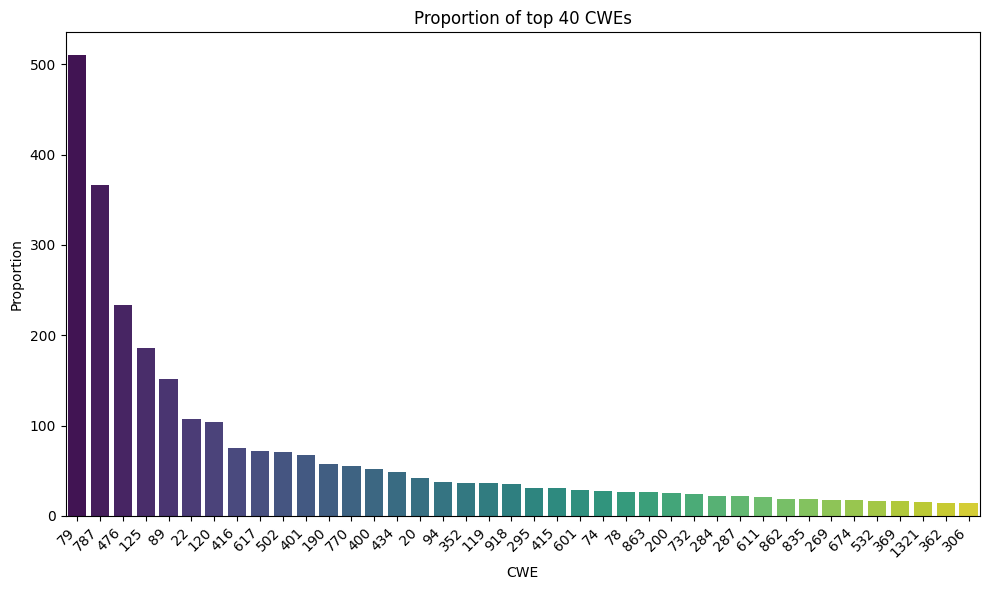

In [102]:
import seaborn as sns
import matplotlib.pyplot as plt

k = 40
data = true_pos_few[true_pos_few["cve_primary_cwe"].apply(lambda x: x != None)][
    "cve_primary_cwe"
].value_counts(normalize=False)
data_df = data.head(40).reset_index()
data_df.columns = ["CWE", "Proportion"]
print("data len:\t", len(data))
display(data_df.head(10))
# Plotting
plt.figure(figsize=(10, 6))
sns.barplot(x="CWE", y="Proportion", hue="CWE", data=data_df, palette="viridis")

# Add labels and title
plt.xticks(rotation=45, ha="right")
plt.title(f"Proportion of top {k} CWEs")

# Show the plot
plt.tight_layout()
plt.show()

In [ ]:
from datasets import load_dataset

test_zero = load_dataset(
    "Eathus/github-issues-vul-detection-gpt-zero-vul-desc-results", split="test"
)
test_zero_df = test_zero.to_pandas()
test_zero_df = test_zero_df[
    ~test_zero_df.duplicated(subset="issue_github_id", keep=False)
]

In [ ]:
true_pos_zero = test_zero_df[test_zero_df.gpt_is_relevant & ~test_zero_df.cve_id.isna()]
false_pos_zero = test_zero_df[test_zero_df.gpt_is_relevant & test_zero_df.cve_id.isna()]
all_true_zero = test_zero_df[test_zero_df.gpt_is_relevant]

print(len(true_pos_zero))
display(true_pos_zero.head(1))
print(len(false_pos_zero))
display(false_pos_zero.head(1))
print("all true:", len(all_true_zero))
print("all", len(test_zero_df))

In [ ]:
true_pos_few.columns

In [ ]:
pd.set_option("display.max_colwidth", None)  # No truncation of column content
pd.set_option("display.max_rows", None)  # Show all rows
pd.set_option("display.max_columns", None)  # Show all columns

In [ ]:
true_pos_few[~true_pos_few.gpt_vulnerability.str.contains("Demonstrative Scenario")][
    "gpt_vulnerability"
]

In [61]:
def bare_rag_label(
    data_df, vectorstore, match_col="gpt_vulnerability", k=1
):  # max for k is 20
    ret_df = data_df.copy()
    faiss_retriever = vectorstore.as_retriever(
        search_kwargs={
            "k": k,
        }
    )
    #ensemble_retriever = EnsembleRetriever(
    #    retrievers=[faiss_retriever],
    #    weights=[1],
    #    # retrievers=[faiss_retriever], weights=[1]
    #)

    # display(ret_df[ret_df['cve_primary_cwe'].isna()])
    def label(desc):
        try:
            ret = list(
                set([x.metadata["CWE_ID"] for x in faiss_retriever.invoke(desc)])
            )
            # print(len(ret))
            return ret
        except Exception as e:
            print(f"General error processing message: {e}")
            return

    ret_df["rag_candidates"] = ret_df[match_col].progress_map(label)
    ret_df["rag_label"] = ret_df.apply(
        lambda row: (
            row["cve_primary_cwe"]
            if row["cve_primary_cwe"] in row["rag_candidates"]
            else row["rag_candidates"][0]
        ),
        axis=1,
    )

    return ret_df

In [95]:
# os.environ["TOKENIZERS_PARALLELISM"] = "false"  # Must be before pandarallel init
rag_labeled_df = bare_rag_label(
    true_pos_few, vectorstore_gpt, match_col="gpt_vulnerability", k=15
)
#display(rag_labeled_df.sample(3))

100%|██████████| 290/290 [00:10<00:00, 26.96it/s]


In [ ]:
rag_labeled_df.columns

In [ ]:
from datasets import Dataset

# test
ds = Dataset.from_pandas(rag_labeled_df.drop(columns='__index_level_0__'))
ds.push_to_hub("Eathus/github-issues-vul-label-rag-results", split="test")

In [79]:
import statistics as stat

cl_lengths = [len(cands) for cands in rag_labeled_df.rag_candidates.to_list()]
print(stat.mean(cl_lengths))
print(stat.median(cl_lengths))
print(max(cl_lengths))
print(min(cl_lengths))

14.951890034364261
15
15
13


In [96]:
evaluate_rag(rag_labeled_df, "rag_label", echo=True)

Accuracy: 0.7759
Classification Report:
              precision    recall  f1-score   support

        1038       0.00      0.00      0.00         0
        1050       1.00      1.00      1.00         1
        1098       0.00      0.00      0.00         0
         115       0.00      0.00      0.00         0
         116       0.00      0.00      0.00         1
         119       1.00      0.38      0.55         8
         120       1.00      0.80      0.89        15
         122       1.00      1.00      1.00         1
         125       1.00      0.31      0.48        16
         129       1.00      1.00      1.00         1
        1333       1.00      1.00      1.00         1
         150       1.00      1.00      1.00         1
         190       1.00      1.00      1.00         4
         195       0.00      0.00      0.00         0
          20       1.00      0.67      0.80         3
         200       0.00      0.00      0.00         1
         212       0.00      0.00      0.

In [25]:
vectorstore_gpt_fusion = create_vectorstore(documents, "tmp/faiss_gpt_fusion_index")

Loading existing vector store...


In [ ]:
def fusion_retrieval(
    vectorstore, bm25, docs, query: str, k: int = 5, alpha: float = 0.5
) -> List[Document]:
    """
    Perform fusion retrieval combining keyword-based (BM25) and vector-based search.

    Args:
    vectorstore (VectorStore): The vectorstore containing the documents.
    bm25 (BM25Okapi): Pre-computed BM25 index.
    query (str): The query string.
    k (int): The number of documents to retrieve.
    alpha (float): The weight for vector search scores (1-alpha will be the weight for BM25 scores).

    Returns:
    List[Document]: The top k documents based on the combined scores.
    """

    epsilon = 1e-8

    # Step 2: BM25 scores
    bm25_scores = bm25.get_scores(query.split())
    bm25_scores = (bm25_scores - np.min(bm25_scores)) / (
        np.max(bm25_scores) - np.min(bm25_scores) + epsilon
    )

    # Build CWE_ID to BM25 score map
    bm25_score_dict = {
        doc.metadata["CWE_ID"]: score for doc, score in zip(docs, bm25_scores)
    }

    # Step 3: Vector search
    vector_results = vectorstore.similarity_search_with_score(
        query, k=vectorstore.index.ntotal
    )
    docs_vec, vec_scores_raw = zip(*vector_results)

    # Normalize vector scores
    vec_scores = 1 - (np.array(vec_scores_raw) - np.min(vec_scores_raw)) / (
        np.max(vec_scores_raw) - np.min(vec_scores_raw) + epsilon
    )

    # Combine scores safely
    def combine(vec, bm25):
        return alpha * vec + (1 - alpha) * bm25

    # Combine scores for docs with matching CWE_IDs
    score_dict = {}
    for doc_vec, vec_score in zip(docs_vec, vec_scores):
        cwe_id = doc_vec.metadata["CWE_ID"]
        if cwe_id in bm25_score_dict:
            bm25_score = bm25_score_dict[cwe_id]
            combined_score = combine(vec_score, bm25_score)
            score_dict[cwe_id] = (doc_vec, combined_score)

    # Sort and return top k documents
    sorted_doc_scores = sorted(score_dict.values(), key=lambda x: x[1], reverse=True)
    return [doc for doc, _ in sorted_doc_scores[:k]]


def fusion_rag_label(
    data_df, vectorstore, bm25_docs, match_col="gpt_vulnerability", k=1, alpha=0.5
):  # max for k is 20
    ret_df = data_df.copy()

    tokenized_docs = [doc.page_content.split() for doc in bm25_docs]
    bm25_retriever = BM25Okapi(tokenized_docs)

    # display(ret_df[ret_df['cve_primary_cwe'].isna()])
    def label(desc):
        try:
            ret = list(
                set(
                    [
                        x.metadata["CWE_ID"]
                        for x in fusion_retrieval(
                            vectorstore, bm25_retriever, bm25_docs, desc, k, alpha
                        )
                    ]
                )
            )
            # print(len(ret))
            return ret
        except Exception as e:
            print(f"General error processing message: {e}")
            return

    ret_df["rag_candidates"] = ret_df[match_col].progress_map(label)
    ret_df["rag_label"] = ret_df.apply(
        lambda row: (
            row["cve_primary_cwe"]
            if row["cve_primary_cwe"] in row["rag_candidates"]
            else row["rag_candidates"][0]
        ),
        axis=1,
    )

    return ret_df

In [69]:
fusion_rag_labeled_df = fusion_rag_label(
    true_pos_few,
    vectorstore_gpt_fusion,
    bm25_docs1,
    match_col="gpt_vulnerability",
    k=20,
    alpha=0.5,
)

100%|██████████| 291/291 [00:15<00:00, 18.68it/s]


In [54]:
import statistics as stat

cl_lengths = [len(cands) for cands in fusion_rag_labeled_df.rag_candidates.to_list()]
print(stat.mean(cl_lengths))
print(stat.median(cl_lengths))
print(max(cl_lengths))
print(min(cl_lengths))

20
20
20
20


In [71]:
evaluate_rag(fusion_rag_labeled_df, "rag_label")

Accuracy: 0.8178694158075601
Classification Report:
              precision    recall  f1-score   support

        1050       1.00      1.00      1.00         1
        1061       0.00      0.00      0.00         0
         116       0.00      0.00      0.00         1
         119       0.54      1.00      0.70         7
         120       1.00      0.86      0.92        14
         122       1.00      1.00      1.00         1
         125       1.00      0.29      0.45        17
        1285       0.00      0.00      0.00         0
        1333       1.00      1.00      1.00         1
         134       0.00      0.00      0.00         0
         150       1.00      1.00      1.00         1
         190       1.00      1.00      1.00         4
          20       1.00      0.67      0.80         3
         200       0.00      0.00      0.00         1
         212       1.00      1.00      1.00         1
          22       1.00      1.00      1.00         1
         280       1.00      

/home/edvinn/anaconda3/envs/mthesis_cpyenv/lib/python3.10/site-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/home/edvinn/anaconda3/envs/mthesis_cpyenv/lib/python3.10/site-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Recall is ill-defined and being set to 0.0 in labels with no true samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/home/edvinn/anaconda3/envs/mthesis_cpyenv/lib/python3.10/site-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{

## RAPTOR

In [ ]:
from datasets import load_dataset
from rag import *

In [ ]:
cwes = load_dataset("Eathus/cwe_view1000_list_gpt_few_cwe_desc", split="train")
cwes_df = cwes.to_pandas()

In [ ]:
from langchain.schema import Document
from rag import *
import pandas as pd
import json

with open("tmp/view_CWE-1000_all_weaknesses.json", "r") as file:
    data = json.load(file)

old_documents = [
    create_ordered_cwe_document(weakness, old=True) for weakness in data["Weaknesses"]
]
document_dict = {doc.metadata["CWE_ID"]: doc for doc in old_documents}
cwes_df["RAG_Doc"] = cwes_df.apply(
    lambda x: Document(
        page_content=x.gpt_cwe_description,
        metadata={
            **document_dict[x.ID].metadata,  # Original metadata
            "Child_IDs": x.Children.tolist(),  # New field
        },
    ),
    axis=1,
)
documents = [
    Document(
        page_content=(
            cwe.Summary if cwe.Abstraction == "Pillar" else cwe.gpt_cwe_description
        ),
        metadata={
            "CWE_ID": cwe.ID,  # Original metadata
            "Abstraction": CWE_abstraction[cwe.Abstraction.upper()].value,  # New field
            "Child_IDs": cwe.Children.tolist(),  # New field
        },
    )
    for _, cwe in cwes_df.iterrows()
]
old_documents = [
    Document(
        page_content=cwe.Summary,
        metadata={
            "CWE_ID": cwe.ID,  # Original metadata
            "Abstraction": CWE_abstraction[cwe.Abstraction.upper()].value,  # New field
            "Child_IDs": cwe.Children.tolist(),  # New field
        },
    )
    for _, cwe in cwes_df.iterrows()
]

In [ ]:
old_norm_documents = [
    create_ordered_cwe_document(weakness, CWE_doc_density.NORM, old=True)
    for weakness in data["Weaknesses"]
]
old_heavy_documents = [
    create_ordered_cwe_document(weakness, CWE_doc_density.HEAVY, old=True)
    for weakness in data["Weaknesses"]
]
old_medium_documents = [
    create_ordered_cwe_document(weakness, CWE_doc_density.MEDIUM, old=True)
    for weakness in data["Weaknesses"]
]

old_norm_documents = [
    Document(
        page_content=doc.page_content,
        metadata={
            "CWE_ID": doc.metadata["CWE_ID"],  # Original metadata
            "Abstraction": doc.metadata["Abstraction"],
            "Child_IDs": cwes_df.loc[cwes_df.ID == doc.metadata["CWE_ID"], "Children"]
            .iloc[0]
            .tolist(),  # New field
        },
    )
    for doc in old_norm_documents
]
old_norm_documents = add_sequential_ids(old_norm_documents)

old_heavy_documents = [
    Document(
        page_content=doc.page_content,
        metadata={
            "CWE_ID": doc.metadata["CWE_ID"],  # Original metadata
            "Abstraction": doc.metadata["Abstraction"],
            "Child_IDs": cwes_df.loc[cwes_df.ID == doc.metadata["CWE_ID"], "Children"]
            .iloc[0]
            .tolist(),  # New field
        },
    )
    for doc in old_heavy_documents
]
old_heavy_documents = add_sequential_ids(old_heavy_documents)

old_medium_documents = [
    Document(
        page_content=doc.page_content,
        metadata={
            "CWE_ID": doc.metadata["CWE_ID"],  # Original metadata
            "Abstraction": doc.metadata["Abstraction"],
            "Child_IDs": cwes_df.loc[cwes_df.ID == doc.metadata["CWE_ID"], "Children"]
            .iloc[0]
            .tolist(),  # New field
        },
    )
    for doc in old_medium_documents
]
old_medium_documents = add_sequential_ids(old_medium_documents)

In [ ]:
def split_docs(docs, echo=False):
    all_docs = []
    for doc in docs:
        all_docs.extend(split_cwe_document(doc))
    all_docs = add_sequential_ids(all_docs)
    if echo:
        print(f"Original: {len(documents)} docs")
        print(f"After splitting: {len(all_docs)} docs")
        print(f"Max tokens: {max(count_tokens(d.page_content) for d in all_docs)}")
    return all_docs

In [ ]:
all_docs = split_docs(documents, True)
old_docs = split_docs(old_documents, True)
bm25_docs0 = [
    Document(
        page_content=cwe.page_content,
        metadata=cwe.metadata,
    )
    for cwe in old_documents
]
bm25_docs1 = [
    Document(
        page_content=remove_subtitle(cwe.page_content, ["Extended Description"]),
        metadata=cwe.metadata,
    )
    for cwe in old_documents
]
all_docs_bm25_0 = split_docs(bm25_docs0, True)
all_docs_bm25_1 = split_docs(bm25_docs1, True)

In [ ]:
from datasets import load_dataset

test_few = load_dataset(
    "Eathus/github-issues-vul-detection-gpt-few-strict-vul-desc-results", split="test"
)
test_few_df = test_few.to_pandas()
test_few_df = test_few_df[~test_few_df.duplicated(subset="issue_github_id", keep=False)]

In [ ]:
true_pos_few = test_few_df[test_few_df.gpt_is_relevant & ~test_few_df.cve_id.isna()]
false_pos_few = test_few_df[test_few_df.gpt_is_relevant & test_few_df.cve_id.isna()]
all_true_few = test_few_df[test_few_df.gpt_is_relevant]

In [ ]:
documents = add_sequential_ids(documents)
raptor_vectorstore_gpt = create_vectorstore(
    all_docs, "tmp/chromadb_indices_gpt", "gpt_index", Vectorstore.CHROMADB
)

In [ ]:
raptor_vectorstore_old = create_vectorstore(
    old_docs, "tmp/chromadb_indices_old", "old_index", Vectorstore.CHROMADB
)

In [ ]:
raptor_vectorstore_gpt_condensed = create_vectorstore(
    documents, "tmp/chromadb_indices_gpt_condensed", "gpt_index", Vectorstore.CHROMADB
)

In [ ]:
raptor_vectorstore_norm = create_vectorstore(
    old_norm_documents, "tmp/chromadb_indices_norm", "norm_index", Vectorstore.CHROMADB
)
raptor_vectorstore_medium = create_vectorstore(
    old_medium_documents,
    "tmp/chromadb_indices_medium",
    "medium_index",
    Vectorstore.CHROMADB,
)
raptor_vectorstore_heavy = create_vectorstore(
    old_heavy_documents,
    "tmp/chromadb_indices_heavy",
    "heavy_index",
    Vectorstore.CHROMADB,
)

In [ ]:
raptor_rag_labeled_df = raptor_rag_label(
    true_pos_few,
    raptor_vectorstore_medium,
    match_col="gpt_vulnerability",
    # device="cpu",
    bm25_docs=old_medium_documents,
    k_list=[3, 12, 4, 1, 1],
    top_abstraction=CWE_abstraction.PILLAR,
    alpha=0.8,
)

display(raptor_rag_labeled_df.sample(3))

In [ ]:
raptor_rag_labeled_df = raptor_rag_label_optimized(
    true_pos_few,
    raptor_vectorstore_gpt,
    match_col="gpt_vulnerability",
    k_list=[4, 7, 4, 2, 1],
    device="cpu",
    max_workers=1,
)

In [ ]:
import statistics as stat

cl_lengths = [len(cands) for cands in raptor_rag_labeled_df.rag_candidates.to_list()]
print(stat.mean(cl_lengths))
print(stat.median(cl_lengths))
print(max(cl_lengths))
print(min(cl_lengths))

In [ ]:
evaluate_rag(raptor_rag_labeled_df)

In [ ]:
from langchain.retrievers import ContextualCompressionRetriever
from langchain.retrievers.document_compressors import LLMChainExtractor
from langchain.llms import OpenAI

OPENAI_API_KEY_KTH = os.getenv("OPENAI_API_KEY_KTH")

llm = OpenAI(temperature=0, api_key=OPENAI_API_KEY_KTH)


def hierarchical_retrieval(
    query: str,
    vectorstore,
    hierarchy_cache,
    k_list: List = [3, 10, 5, 2, 1],
    top_abstraction=CWE_abstraction.PILLAR,
) -> List[Document]:

    k_dict = {
        "PILLAR": k_list[0],
        "CLASS": k_list[1],
        "BASE": k_list[2],
        "VARIANT": k_list[3],
        "COMPOUND": k_list[4],
    }

    all_retrieved_docs = []
    child_ids = None  # Initialize child_ids
    level = top_abstraction
    compressor = LLMChainExtractor.from_llm(llm)

    i = 0

    while True:
        # Define metadata filter
        CWE_abstraction(i)
        if child_ids:
            filter_condition = {"CWE_ID": {"$in": child_ids}}
        else:
            filter_condition = {"Abstraction": {"$eq": level.value}}

        base_retriever = vectorstore.as_retriever(
            search_kwargs={"k": k_dict[level.name], "filter": filter_condition}
        )
        compression_retriever = ContextualCompressionRetriever(
            base_compressor=compressor, base_retriever=base_retriever
        )

        # Retrieve documents with the defined filter
        level_docs = compression_retriever.invoke(query)
        all_retrieved_docs.extend(level_docs)

        # Prepare child_ids for the next iteration
        if level_docs:
            max_level = max([doc.metadata.get("Abstraction", 0) for doc in level_docs])
            level = CWE_abstraction(max_level)
            child_ids = []
            for doc in level_docs:
                child_ids.extend(
                    hierarchy_cache.get(doc.metadata["CWE_ID"], {}).get("children", [])
                )
            child_ids = list(set(child_ids))
        else:
            child_ids = None  # Reset if no documents found or at the lowest level

        if not child_ids or i > 4:
            break

        i += 1
    return list({doc.metadata["id"]: doc for doc in all_retrieved_docs}.values())

In [ ]:
def raptor_hierarchy_rag_label(
    data_df,
    vectorstore,
    match_col="gpt_vulnerability",
    k_list: List = [3, 10, 5, 2, 0],
    # max_workers=10,
    top_abstraction=CWE_abstraction.PILLAR,
    max_workers=15,
):  # max for k is 20
    ret_df = data_df.copy()

    hierarchy_cache = {}
    all_metadata = vectorstore.get()["metadatas"]
    for meta in all_metadata:
        hierarchy_cache[meta["CWE_ID"]] = {
            "abstraction": meta["Abstraction"],
            "children": meta["Child_IDs"].split(",") if meta.get("Child_IDs") else [],
        }
    # display(ret_df[ret_df['cve_primary_cwe'].isna()])

    def label(desc):
        try:
            ret = [
                x.metadata["CWE_ID"]
                for x in hierarchical_retrieval(
                    desc,
                    vectorstore,
                    k_list=k_list,
                    hierarchy_cache=hierarchy_cache,
                    top_abstraction=top_abstraction,
                )
            ]
            # print(len(ret))
            return ret
        except Exception as e:
            print(f"General error processing message: {e}")
            return

    with ThreadPoolExecutor(max_workers=max_workers) as executor:
        queries = data_df[match_col].tolist()
        results = list(
            tqdm(
                executor.map(label, queries),
                total=len(queries),
                desc="Processing RAG queries",
            )
        )

    # 4. Create final dataframe
    ret_df = data_df.copy()
    ret_df["rag_candidates"] = results
    ret_df["rag_label"] = ret_df.apply(
        lambda row: (
            row["cve_primary_cwe"]
            if row["cve_primary_cwe"] in row["rag_candidates"]
            else (row["rag_candidates"][0] if row["rag_candidates"] else None)
        ),
        axis=1,
    )
    return ret_df

In [ ]:
raptor_rag_labeled_df = raptor_hierarchy_rag_label(
    true_pos_few,
    raptor_vectorstore_gpt,
    match_col="gpt_vulnerability",
    # device="cpu",
    k_list=[3, 8, 4, 1, 1],
    top_abstraction=CWE_abstraction.PILLAR,
)

In [ ]:
import statistics as stat

cl_lengths = [len(cands) for cands in raptor_rag_labeled_df.rag_candidates.to_list()]
print(stat.mean(cl_lengths))
print(stat.median(cl_lengths))
print(max(cl_lengths))
print(min(cl_lengths))

evaluate_rag(raptor_rag_labeled_df)

## Reranking 

In [ ]:
import sys
from pathlib import Path

# Get parent directory (Thesis-Edvin)
sys.path.append(str(Path.cwd().parent))

In [ ]:
from utils import *
from rag import *
from langchain_openai import ChatOpenAI
from langchain import PromptTemplate
from pydantic import BaseModel, Field
from langchain_core.retrievers import BaseRetriever
from langchain.chains import RetrievalQA
from typing import List
from openai import OpenAIError, RateLimitError

In [ ]:
class RatingScore(BaseModel):
    relevance_score: float = Field(..., description="The relevance score of a document to a query.")

def rerank_documents(query: str, docs: List[Document], top_n: int = 3) -> List[Document]:
    prompt_template = PromptTemplate(
        input_variables=["vulnerability", "doc"],
        template="""On a scale of 1-10, rate the relevance of the following document to the vulnerability. Consider the specific context and intent of the vulnerability, not just keyword matches.
        Vulnerability: {vulnerability}
        Document: {doc}
        Relevance Score:"""
    )
    
    llm = ChatOpenAI(temperature=0, model_name="gpt-4o-mini", max_tokens=4000, api_key=OPENAI_API_KEY_KTH)
    llm_chain = prompt_template | llm.with_structured_output(RatingScore)
    
    scored_docs = []
    for doc in docs:
        input_data = {"vulnerability": query, "doc": doc.page_content}
        try:
            score = llm_chain.invoke(input_data).relevance_score
        except OpenAIError as e:  # Catch all OpenAI-specific errors
            print(f"OpenAI API error: {e}")
        except Exception as e:
            print(f"General error processing message: {e}")
        try:
            score = float(score)
        except ValueError:
            score = 0  # Default score if parsing fails
        scored_docs.append((doc, score))
    
    reranked_docs = sorted(scored_docs, key=lambda x: x[1], reverse=True)
    return [doc for doc, _ in reranked_docs[:top_n]]

In [ ]:
class CustomRetriever(BaseRetriever):
    
    vectorstore : FAISS = Field(description="Vector store for initial retrieval")

    def _get_relevant_documents(self, query: str, num_docs=2) -> List[Document]:
        initial_docs = self.vectorstore.similarity_search(query, k=30)
        return rerank_documents(query, initial_docs, top_n=num_docs)


# Create the custom retriever
custom_retriever = CustomRetriever(vectorstore=vectorstore_gpt)

# Create an LLM for answering questions



In [ ]:
from pandarallel import pandarallel
pandarallel.initialize(progress_bar=True, nb_workers=15)

os.environ["TOKENIZERS_PARALLELISM"] = "false"

def rerank_rag_label(
    data_df, vectorstore, match_col="gpt_vulnerability", k=1, max_workers=15
):  # max for k is 20
    ret_df = data_df.copy()

    custom_retriever = CustomRetriever(vectorstore=vectorstore)
    # display(ret_df[ret_df['cve_primary_cwe'].isna()])
    def label(desc):
        try:
            ret = list(
                set([x.metadata["CWE_ID"] for x in custom_retriever._get_relevant_documents(desc, k)])
            )
            # print(len(ret))
            return ret
        except Exception as e:
            print(f"General error processing message: {e}")
            return
    '''
    ret_df["rag_candidates"] = ret_df[match_col].progress_map(lambda x: label(x))
    ret_df["rag_label"] = ret_df.apply(
        lambda row: (
            row["cve_primary_cwe"]
            if row["cve_primary_cwe"] in row["rag_candidates"]
            else row["rag_candidates"][0]
        ),
        axis=1,
    )
    '''
    with ThreadPoolExecutor(max_workers=max_workers) as executor:
        queries = data_df[match_col].tolist()
        results = list(
            tqdm(
                executor.map(label, queries),
                total=len(queries),
                desc="Processing RAG queries",
            )
        )
    ret_df = data_df.copy()
    ret_df["rag_candidates"] = results
    ret_df["rag_label"] = ret_df.apply(
        lambda row: (
            row["cve_primary_cwe"]
            if row["cve_primary_cwe"] in row["rag_candidates"]
            else (row["rag_candidates"][0] if row["rag_candidates"] else None)
        ),
        axis=1,
    )

    return ret_df

In [ ]:
rag_labeled_df = rerank_rag_label(
    true_pos_few, vectorstore_gpt, match_col="gpt_vulnerability", k=1
)

In [ ]:
import statistics as stat

cl_lengths = [len(cands) for cands in rag_labeled_df.rag_candidates.to_list()]
print(stat.mean(cl_lengths))
print(stat.median(cl_lengths))
print(max(cl_lengths))
print(min(cl_lengths))
evaluate_rag(rag_labeled_df, "rag_label")

## Generation step

In [1]:
import sys
from pathlib import Path

# Get parent directory (Thesis-Edvin)
sys.path.append(str(Path.cwd().parent))

In [2]:
from utils import *

In [3]:
from datasets import load_dataset
cwes = load_dataset("Eathus/cwe_view1000_list_gpt_few_cwe_desc", split="train")
cwe_df = cwes.to_pandas()

In [4]:
old_heavy_documents[0].metadata

NameError: name 'old_heavy_documents' is not defined

In [5]:
from langchain.schema import Document
from rag import *
import pandas as pd
import json

with open("tmp/view_CWE-1000_all_weaknesses.json", "r") as file:
    data = json.load(file)

In [6]:
cwe_dict = {dat['ID']: dat for dat in data["Weaknesses"]}

In [209]:
def create_ordered_cwe_dict(weakness, doc_density=CWE_doc_density.LIGHT, old=False):
    ret =  {
        "ID": weakness["ID"],
        "Description": weakness['Description'],
        **({"ExtendedDescription": weakness['ExtendedDescription']} if "ExtendedDescription" in weakness else {}),
    }
    
    if doc_density in [CWE_doc_density.NORM, CWE_doc_density.HEAVY] and "AlternateTerms" in weakness :
        ret["AlternateTerms"] = weakness["AlternateTerms"]
    
    if doc_density in [CWE_doc_density.HEAVY] :
        if "CommonConsequences" in weakness:
            ret["CommonConsequences"] = weakness["CommonConsequences"]
        if "AffectedResources" in weakness:
            ret["AffectedResources"] = weakness["AffectedResources"]
        if "ModesOfIntroduction" in weakness:
            ret["ModesOfIntroduction"] = weakness["ModesOfIntroduction"]
        if "BackgroundDetails" in weakness:
            ret["BackgroundDetails"] = weakness["BackgroundDetails"]
    

    if doc_density in [CWE_doc_density.NORM, CWE_doc_density.HEAVY]:
        if "Notes" in weakness:
            ret["Notes"] = weakness["Notes"]
        if "ObservedExamples" in weakness:
            ret["ObservedExamples"] = [ ex['Description'] for ex in weakness["ObservedExamples"]]        

    if "DemonstrativeExamples" in weakness:
        if doc_density in [CWE_doc_density.LIGHT, CWE_doc_density.NORM] :
            ret["DemonstrativeExample"] = weakness['DemonstrativeExamples'][0]
        else :
            ret["DemonstrativeExamples"] = weakness['DemonstrativeExamples']
    
    return ret

In [ ]:
def cwe_list_to_json_str(cwes, cwe_dict, indent=4, doc_density=CWE_doc_density.LIGHT):
    js_list = [create_ordered_cwe_dict(cwe_dict[cwe], doc_density) for cwe in cwes]
    return json.dumps({"Weaknesses": js_list}, indent=indent)

In [211]:
import os
from langchain_openai import ChatOpenAI
from langchain_core.prompts import ChatPromptTemplate
from pydantic import BaseModel, Field
from utils import *


class ReplySchema(BaseModel):
    gpt_cwe: str = Field(
        description="The CWE-ID (*only the number*) of the CWE entry that best fits the vulnerability description"
    )
    gpt_cwe_confidence: int = Field(
        description="An integer from 1 to 5 indicating your level of confidence  (1 = very low, 2 = low, 3 = medium, 4 = high, 5 = very high)."
    )


llm = ChatOpenAI(
    model="gpt-4o-mini",
    temperature=0.0,
    api_key=OPENAI_API_KEY_KTH,  # <- this overrides the default
)  # maybe set max_token to 14000

prompts_dict = load_prompts(os.getcwd() + "/../utils/prompts")

prompt = ChatPromptTemplate.from_messages(
    [("system", prompts_dict["RAG_system_setup_json"]), ("human", "{desc}")],
)


def parser(message: ReplySchema):
    return message.model_dump_json()


llm = llm.with_structured_output(ReplySchema)
chain = prompt | llm | parser

In [212]:
from utils import *
from pandarallel import pandarallel
from tenacity import (
    retry,
    stop_after_attempt,
    wait_exponential,
    retry_if_exception_type,
)
from openai import OpenAIError, RateLimitError  # Explicitly import errors

pandarallel.initialize(progress_bar=True, nb_workers=15)

@retry(
    stop=stop_after_attempt(5),  # Retry up to 5 times
    wait=wait_exponential(multiplier=2, min=1, max=60),  # Exponential backoff
    retry=retry_if_exception_type(RateLimitError),  # Retry only on rate limit errors
)
def _gpt_classify(desc, cwe_entries):
    if (
        not desc
        or not isinstance(desc, str)
        or not cwe_entries
        or not isinstance(cwe_entries, str)
    ):  # Check for empty/invalid messages
        return None
    return chain.invoke(
        {
            "cwe_entries": cwe_entries,
            "desc": desc,
        }
    )  # Adjusted for OpenAI API format


def gpt_classify(desc, cwe_entries):
    try:
        return _gpt_classify(desc, cwe_entries)
    except OpenAIError as e:  # Catch all OpenAI-specific errors
        print(f"OpenAI API error: {e}")
    except Exception as e:
        print(f"General error processing message: {e}")
    return None

INFO: Pandarallel will run on 15 workers.
INFO: Pandarallel will use Memory file system to transfer data between the main process and workers.


In [213]:
len(rag_labeled_df)

291

In [214]:
import pickle
import os

file_path = "tmp/rag_cwe_pred_max_small2.pkl"

# Define the path to your pickle file

# Check if the file exists
if os.path.exists(file_path):
    with open(file_path, "rb") as file:
        rag_labeled_df = pickle.load(file)
    print("Pickle file loaded successfully!")
else:
    print(f"The file at {file_path} does not exist. Setting gpt_response to 'None'")
    rag_labeled_df["rag_prediction"] = None

The file at tmp/rag_cwe_pred_max_small2.pkl does not exist. Setting gpt_response to 'None'


In [215]:
def cwe_list_to_md_str(cwes, md_documents):
    markdown_list = [doc.page_content for doc in md_documents if doc.metadata['CWE_ID'] in cwes]
    return "\n".join(markdown_list)

In [216]:
print(rag_labeled_df.columns)
rag_labeled_df.iloc[0].cve_primary_cwe

Index(['cve_id', 'cve_published', 'cve_descriptions', 'cve_metrics',
       'cve_references', 'cve_configurations', 'cve_primary_cwe', 'cve_tags',
       'issue_owner_repo', 'issue_body', 'issue_title', 'issue_comments_url',
       'issue_comments_count', 'issue_created_at', 'issue_updated_at',
       'issue_html_url', 'issue_github_id', 'issue_number', 'label',
       'issue_msg', 'issue_msg_n_tokens', 'issue_embedding',
       '__index_level_0__', 'gpt_description', 'gpt_vulnerability',
       'gpt_confidence', 'gpt_is_relevant', 'rag_candidates', 'rag_label',
       'rag_prediction'],
      dtype='object')


'415'

In [217]:
test_rag = gpt_classify(
    rag_labeled_df.iloc[0].gpt_vulnerability,
    cwe_list_to_json_str(rag_labeled_df.iloc[0].rag_candidates, cwe_dict, doc_density=CWE_doc_density.HEAVY),
)

In [ ]:
test_rag

In [218]:
import statistics as stat

requests = [
    [
        {
            'role': 'system',
            'content': prompts_dict["RAG_system_setup"].format(
                cwe_entries=cwe_list_to_json_str(row.rag_candidates, cwe_dict, doc_density=CWE_doc_density.HEAVY)
            )
        },
        {
            'role': 'user',
            'content': row.gpt_vulnerability
        }
    ]
    for _, row in rag_labeled_df[['gpt_vulnerability', 'rag_candidates']].iterrows()
]   
token_counts = [count_chat_tokens(request) for request in requests]

print('Mean token count:\t\t', stat.mean(token_counts))
print('Median token count:\t\t', stat.median(token_counts))
print('Max token count:\t\t', max(token_counts))
print('Min token count:\t\t', min(token_counts))


Mean token count:		 18113.18213058419
Median token count:		 19286
Max token count:		 29939
Min token count:		 4796


In [219]:
rag_labeled_df = rag_labeled_df.reset_index(drop=True)
#display(rag_labeled_df.head(3))
len(rag_labeled_df)

291

In [ ]:
print(rag_labeled_df.loc[na_indices, ["gpt_vulnerability", "rag_candidates"]].head())


In [220]:
import pickle
import time
import os

os.environ["TOKENIZERS_PARALLELISM"] = "false"


retries = 0
max_retries = 10
#file_path = "tmp/rag_cwe_pred.pkl"
DELAY = 1
# test_df['gpt_response'] = None
while (
    not rag_labeled_df[rag_labeled_df.rag_prediction.isna()].empty
    and retries < max_retries
):
    # Get indices of rows needing processing
    na_indices = rag_labeled_df[
        rag_labeled_df.rag_prediction.isna() & ~rag_labeled_df.cve_id.isna()
    ].index

    if len(na_indices) == 0:
        break

    # Process ONLY those rows and assign directly to original DF
    rag_labeled_df.loc[na_indices, "rag_prediction"] = rag_labeled_df.loc[
        na_indices, ["gpt_description", "rag_candidates"]
    ].parallel_apply(
        lambda x: gpt_classify(
            x["gpt_description"], cwe_list_to_json_str(x["rag_candidates"], cwe_dict, doc_density=CWE_doc_density.HEAVY)
        ),
        axis=1
    )

    with open(file_path, "wb") as file:  # 'wb' mode writes in binary format
        pickle.dump(rag_labeled_df, file)
    retries += 1
    print(f"Retry {retries}: Processed {len(na_indices)} rows")
    time.sleep(DELAY)

Retry 1: Processed 291 rows


In [181]:
rag_labeled_df.rag_prediction.head(5)

0     {"gpt_cwe":"415","gpt_cwe_confidence":5}
1    {"gpt_cwe":"1393","gpt_cwe_confidence":5}
2     {"gpt_cwe":"122","gpt_cwe_confidence":5}
3      {"gpt_cwe":"89","gpt_cwe_confidence":5}
4     {"gpt_cwe":"913","gpt_cwe_confidence":5}
Name: rag_prediction, dtype: object

In [182]:
rag_labeled_df['rag_prediction'].head(5)

0     {"gpt_cwe":"415","gpt_cwe_confidence":5}
1    {"gpt_cwe":"1393","gpt_cwe_confidence":5}
2     {"gpt_cwe":"122","gpt_cwe_confidence":5}
3      {"gpt_cwe":"89","gpt_cwe_confidence":5}
4     {"gpt_cwe":"913","gpt_cwe_confidence":5}
Name: rag_prediction, dtype: object

In [221]:
import json
import pandas as pd

rag_labeled_df['rag_prediction'] = rag_labeled_df['rag_prediction'].map(
    lambda x: json.loads(x) if pd.notna(x) else None
)

In [222]:
test_df = rag_labeled_df.copy()
test_df[['rag_prediction', 'rag_confidence']] = test_df['rag_prediction'].apply(
    lambda x: pd.Series({"1":x['gpt_cwe'], "2":x['gpt_cwe_confidence']}) if pd.notna(x) else None
)
test_df[["rag_prediction", "rag_confidence"]].head(5)

,rag_prediction,rag_confidence
0,415,5
1,1393,5
2,122,5
3,89,5
4,416,4


In [185]:
test_df.columns

Index(['cve_id', 'cve_published', 'cve_descriptions', 'cve_metrics',
       'cve_references', 'cve_configurations', 'cve_primary_cwe', 'cve_tags',
       'issue_owner_repo', 'issue_body', 'issue_title', 'issue_comments_url',
       'issue_comments_count', 'issue_created_at', 'issue_updated_at',
       'issue_html_url', 'issue_github_id', 'issue_number', 'label',
       'issue_msg', 'issue_msg_n_tokens', 'issue_embedding',
       '__index_level_0__', 'gpt_description', 'gpt_vulnerability',
       'gpt_confidence', 'gpt_is_relevant', 'rag_candidates', 'rag_label',
       'rag_prediction', 'rag_confidence'],
      dtype='object')

In [223]:
from sklearn.metrics import accuracy_score, classification_report
import pandas as pd

def evaluate_rag(df, col, echo=False, md_filename="tmp/classification_report.md"):
    y_test = df.cve_primary_cwe
    y_pred = df[col]

    # Evaluate the model
    accuracy = accuracy_score(y_test, y_pred)
    report = classification_report(y_test, y_pred, zero_division=0, output_dict=True)

    print(f"Accuracy: {accuracy:.4f}")
    print("Classification Report:")
    print(classification_report(y_test, y_pred, zero_division=0))

    if echo:
        # Convert to DataFrame
        report_df = pd.DataFrame(report).transpose()

        # Round for nicer output
        report_df = report_df.round(4)

        # Rename the index column
        report_df.index.name = "CWE"

        # Write Markdown
        with open(md_filename, "w") as f:
            f.write("# Classification Report\n\n")
            f.write(f"**Overall Accuracy:** `{accuracy:.4f}`\n")
            f.write(report_df.to_markdown())

        print(f"\n✅ Markdown report saved to: {md_filename}")


In [224]:
evaluate_rag(test_df, "rag_prediction", echo=True)

Accuracy: 0.4880
Classification Report:
              precision    recall  f1-score   support

        1050       0.00      0.00      0.00         1
         114       0.00      0.00      0.00         0
         115       0.00      0.00      0.00         0
         116       0.00      0.00      0.00         1
        1176       0.00      0.00      0.00         0
         119       0.00      0.00      0.00         7
         120       0.50      0.47      0.48        15
         121       0.00      0.00      0.00         0
         122       0.02      1.00      0.05         1
         125       1.00      0.18      0.30        17
        1287       0.00      0.00      0.00         0
         129       0.50      1.00      0.67         1
        1333       1.00      1.00      1.00         1
        1335       0.00      0.00      0.00         0
        1393       0.00      0.00      0.00         0
         150       1.00      1.00      1.00         1
         190       0.75      0.75      0.